<a href="https://colab.research.google.com/github/sytluc0803/MSSP607/blob/main/Modules/Week_12/Week_12_Ex.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata
import os

github_token = userdata.get('Git_Key')
owner = 'sytluc0803'
repository = 'MSSP607'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directory to: {os.getcwd()}")

Changed directory to: /content/MSSP607


In [2]:
%pushd "/content/MSSP607/Modules/Week_12"

/content/MSSP607/Modules/Week_12


['/content/MSSP607']

In [3]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools

In [5]:
df = pd.read_csv("Student Performance Data.csv")
df.head(15)

,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium
1,female,group C,some college,standard,69,90,88,247,completed,high
2,female,group B,master's degree,standard,90,95,93,278,none,high
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low
4,male,group C,some college,standard,76,78,75,229,none,high
5,female,group B,associate's degree,standard,71,83,78,232,none,high
6,female,group B,some college,standard,88,95,92,275,completed,high
7,male,group B,some college,free/reduced,40,43,39,122,none,low
8,male,group D,high school,free/reduced,64,64,67,195,completed,medium
9,female,group B,high school,free/reduced,38,60,50,148,none,low


In [9]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'math score', 'reading score', 'writing score', 'total score',
       'test preparation course', 'admission prospect'],
      dtype='object')

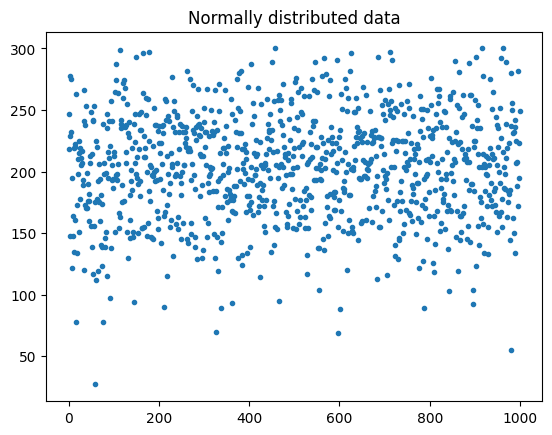

Shapiro-Wilk statistic: 0.9931508136945459
P-value: 0.00014534056593312218


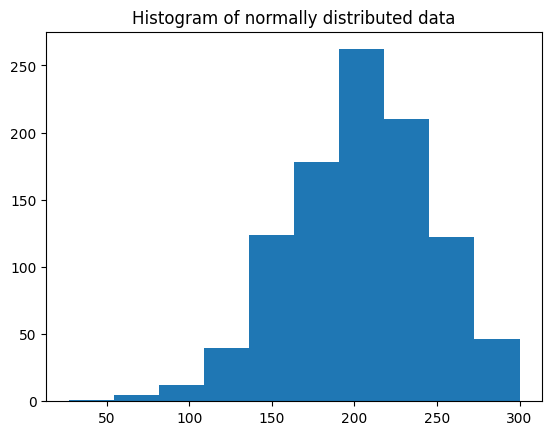

In [16]:
plt.plot(df['total score'], '.')
plt.title('Normally distributed data')
plt.show()

plt.hist(df['total score'])
plt.title('Histogram of normally distributed data')

from scipy.stats import shapiro

# Remove missing values
scores = df["total score"].dropna()

# Shapiro-Wilk test
stat, p_value = shapiro(scores)

print("Shapiro-Wilk statistic:", stat)
print("P-value:", p_value)

In [12]:
male = df.loc[df["gender"] == "male", "total score"].dropna()

others = df.loc[df["gender"] != "male", "total score"].dropna()

In [13]:
# Welch's independent two-sample t-test, which does not assume equal variances between the two groups

from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(male, others, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -4.178885983407181
P-value: 3.18619756387528e-05


In [14]:
# Null Hypo: The mean total score of male test takers is equal to that of other test takers.
# Alt Hypo: The mean total score of male test takers differs from that of other test takers


alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is a statistically significant difference in mean total scores.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a difference in mean total scores.")

Reject the null hypothesis.
There is a statistically significant difference in mean total scores.
